# Codes that are not CSS, step by step: the isometry AP normal form and the logical action

> **In short.**
> * **The question.** Question 2 (what does a block do to the encoded qubits?) compares the block with the ideal encoders of the codes before and after it. For a CSS code the tool writes the encoder as a two-layer diagram; for any other stabilizer code it uses the *isometry affine-with-phases normal form* (IAPNF) of *A Three-Way Normal Form for Stabiliser Codes across ZX Diagrams, Circuits, and Tableaus* (QPL 2026): $E = U_O \cdot C \cdot U_I$, a Clifford $U_I$ on the logical qubits, a phase-free CSS core $C$, and a diagonal Clifford $U_O$ on the physical qubits.
> * **Why.** When the block is diagonal (a layer of $Z$-rotations such as $T$) and both codes have the same $U_O$, the two $U_O$ cancel around it, since diagonal maps commute. The block is then checked on the CSS core, exactly as for a CSS code.
> * **The example.** The repetition code of the paper's running example ($X_0X_1$, $X_1X_2$), made non-CSS by an $S$ on qubit 0, followed by a $T$ on the parity of the three qubits. Small enough to print every matrix.
> * **The steps.** (1) the codes; (2) the encoder through its Choi state; (3) the reduced AP form of the Choi state; (4) the IAPNF, by Algorithm 3 of the three-way normal form paper; (5) the logical action through the normal forms, where $U_O$ cancels and the block is checked on the core; (6) the same answer through the ideal encoders, for comparison.
> * **Library calls only**: PyZX's OpenQASM reader, `QProgram`, `code_at`, `reduced_ap_form`, `iap_normal_form`, `logical_action`, `reduce_gpf`, `phase_polynomial`. The broader tour of codes that are not CSS is [StabilizerCodes.ipynb](StabilizerCodes.ipynb).

In [1]:
%matplotlib inline
import numpy as np
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.utils import VertexType
from zxqec.qprogram import QProgram
from zxqec.codes import iap_normal_form, logical_action, reduced_ap_form
from zxqec.gpf import phase_polynomial, reduce_gpf, same_map
from zxqec.spacetime import draw_program

## The program

Qubit 0 is the input. The first stage encodes it into the repetition code of the paper (copy it onto qubits 1 and 2 with CNOTs, then a Hadamard on every qubit: the checks $X_0X_1$ and $X_1X_2$). The second stage is an $S$ on qubit 0. The third is the block: CNOTs collect the parity of the three qubits on qubit 2, a $T$ acts on it, and the CNOTs are undone, a diagonal map $\lvert x\rangle \mapsto e^{i\pi/4 \cdot (x_0 \oplus x_1 \oplus x_2)} \lvert x\rangle$.

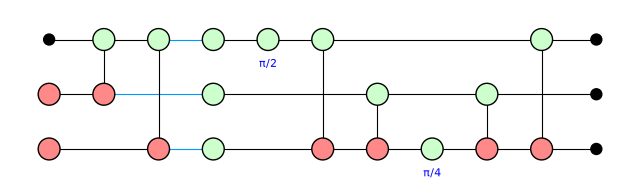

In [2]:
HEADER = 'OPENQASM 2.0;\ninclude "qelib1.inc";\nqreg q[3];\n'
STAGES = [('encode', 'cx q[0], q[1]; cx q[0], q[2];\nh q[0]; h q[1]; h q[2];\n'),
          ('S on qubit 0', 's q[0];\n'),
          ('T on the parity', 'cx q[0], q[2]; cx q[1], q[2];\nt q[2];\ncx q[1], q[2]; cx q[0], q[2];\n')]
p = QProgram(3, initial_states={1: '0', 2: '0'})
for name, text in STAGES:
    p.add_circuit(Circuit.from_qasm(HEADER + text), name=name)
draw_program(p, time_axis=False, show_time=False, even_rows=True, figsize=(8, 2.2))

## Step 1: the codes (Question 1)

After the encoder, the repetition code. After the $S$, the same code space turned by $S$ on qubit 0: $S X S^\dagger = Y$, so each stabilizer that has an $X$ on qubit 0 now has a $Y$ there, and the code is not CSS. Its logical $X$ is chosen from the stabilizers alone (Question 1): a string of $X$s only that commutes with every stabilizer, now $X_1$, since $X_0$ no longer commutes with $Y_0X_1$.

In [3]:
print("after the encoder:"); print(p.code_at(0))
print("after S on qubit 0:"); print(p.code_at(1))
code = p.code_at(1)
print("CSS:", code.is_css)

after the encoder:
[[3, 1, 1]] CSS code on qubits 0, 1, 2
    stabilizer +XXI
    stabilizer +XIX
    logical X XII   logical Z ZZZ
after S on qubit 0:
[[3, 1, 1]] stabilizer code on qubits 0, 1, 2
    stabilizer +IXX
    stabilizer +YXI
    logical X IXI   logical Z ZZZ
CSS: False


## Step 2: the encoder through its Choi state

The ideal encoder $E$ is the isometry with $E \circ X = \bar X \circ E$ and $E \circ Z = \bar Z \circ E$ whose image is the code space. Bend its input round, and it becomes a state on $k + n = 4$ qubits, its *Choi state* $\sum_x \lvert x\rangle \otimes E\lvert x\rangle$ (the logical qubit first). This state is fixed by $n + k = 4$ independent commuting Pauli strings: $I \otimes g$ for each stabilizer $g$ (because $gE = E$), and $X \otimes \bar X$ and $Z \otimes \bar Z$ (exactly because of the two equations above). So the code's description, its stabilizers and logical operators, determines the Choi state, and with it $E$.

In [4]:
print("generators of the Choi state (logical qubit first):")
for g in code.stabilizers:
    print("   I (x)", g)
print("   X (x)", code.logical_x[0])
print("   Z (x)", code.logical_z[0])

generators of the Choi state (logical qubit first):
   I (x) +IXX
   I (x) +YXI
   X (x) +IXI
   Z (x) +ZZZ


## Step 3: the reduced AP form of the Choi state

Every stabilizer state can be written in *affine-with-phases* (AP) form (the three-way normal form paper, Definition 4.1): a uniform superposition over the bit strings $a$ with $Ba = b$, with the phase $i^{\sum_f A_{ff} a_f} (-1)^{\sum_{f<g} A_{fg} a_f a_g}$. In the *reduced* form, $(B, b)$ is in reduced row echelon form with the inputs first, so that an input is a pivot whenever it can be, and $A$ is non-zero only on the free variables (the columns that are not pivots).

`reduced_ap_form` computes it from the generators of step 2. The rows of $(B, b)$ are the stabilizers of the Choi state that have no $X$ part ($Z^c (-1)^b$ fixes the state exactly when $c \cdot a = b$ on every term), brought to reduced row echelon form. For each free variable $f$, the stabilizer whose $X$ part is 1 on $f$ (and on the pivots what $B$ then forces) gives row $f$ of $A$: its $Z$ part on the other free variables is $A_{fg}$, and its phase is $i^{A_{ff}}$. All of this is Gaussian elimination over $\mathbb{F}_2$ on $n + k$ variables.

In [5]:
ap = reduced_ap_form(code)
print(ap)

reduced AP form on 4 variables: in0, 0, 1, 2
  rows of B (X-spiders): {in0, 0, 1, 2}, pivot in0
  free variables: 0, 1, 2
  phases: 0: pi/2
  CZ: none


One row, $\{\mathrm{in}_0, 0, 1, 2\}$ with $b = 0$: every term has an even number of ones among the input and the three qubits. Its pivot is the input, so the outputs are free. $A_{00} = 1$: a term with $a_0 = 1$ gets the phase $i$, which is the $S$ on qubit 0. There is no $A_{fg}$, so no CZ. In ZX, the form is a green spider on each variable, a red spider for the row joined to its variables, a phase $A_{ff}\,\pi/2$ on each free variable and a Hadamard edge for each $A_{fg} = 1$; with the input variable drawn as an input, it is the encoder itself:

the same map as the ideal encoder: True


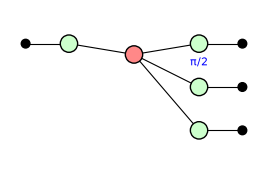

In [6]:
print("the same map as the ideal encoder:", same_map(ap.to_graph(inputs=1), code.encoder()))
zx.draw_matplotlib(ap.to_graph(inputs=1), figsize=(3.2, 2))

## Step 4: the isometry AP normal form (the three-way normal form paper, Algorithm 3)

`iap_normal_form` cuts the reduced AP form into three layers, $E = U_O \cdot C \cdot U_I$:

1. **Cut off $U_I$ and $U_O$.** $A$ between free inputs gives $U_I$'s phases and CZ gates; $A$ between free outputs gives $U_O$'s. Here no input is free, so $U_I$ has none, and the phase on output 0 is $U_O$: the $S$.
2. **The inputs, top to bottom.** An input that is a pivot is the red spider of its row (Case 1); an input that is not gets a Hadamard and becomes the pivot of a new red spider, with an X-CZ gate to each earlier pivot input whose row it was in (Cases 2 and 3). Here the input is the pivot of the only row: Case 1, its red spider joined to qubits 0, 1 and 2.
3. **The Z-checks.** The rows whose pivot is an output are the Z-checks of the core. Here there are none.

The core $C$ is phase-free and CSS: it is the encoder of the plain repetition code, and the $S$ lives only in $U_O$. The normal form is unique, so the same code always gives the same layers.

isometry AP normal form: 1 input(s) -> 3 output(s)
  U_I   phases none; CZ none; H on inputs none; X-CZ none
  core  input X-spiders: input 0 -> outputs {0, 1, 2}
        Z-check X-spiders: none
  U_O   phases 0: pi/2; CZ none
the same map as the ideal encoder: True

the repetition code before the S:
isometry AP normal form: 1 input(s) -> 3 output(s)
  U_I   phases none; CZ none; H on inputs none; X-CZ none
  core  input X-spiders: input 0 -> outputs {0, 1, 2}
        Z-check X-spiders: none
  U_O   phases none; CZ none
its encoder is the core above: True


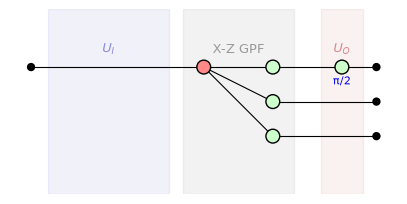

In [7]:
nf = iap_normal_form(code)
print(nf)
print("the same map as the ideal encoder:", same_map(nf.to_graph(), code.encoder()))
print()
print("the repetition code before the S:")
print(iap_normal_form(p.code_at(0)))
print("its encoder is the core above:", same_map(nf.to_graph(u_i=False, u_o=False), iap_normal_form(p.code_at(0)).to_graph()))
nf.draw(figsize=(5, 2.4))

## Step 5: the logical action of the block, through the normal forms

With both encoders in normal form,
$$L = E_\mathrm{out}^\dagger\, B\, E_\mathrm{in} = U_I^{\mathrm{out}\,\dagger}\, C_\mathrm{out}^\dagger\, U_O^{\mathrm{out}\,\dagger}\; B\; U_O^\mathrm{in}\, C_\mathrm{in}\, U_I^\mathrm{in}.$$
The block is diagonal: its reduced diagram is the identity on each qubit with one phase gadget. The code after the block is the same as before, with the same $U_O$. Diagonal maps commute, so $U_O^\dagger B\, U_O = B$, and since $U_I$ is empty here,
$$L = C^\dagger\, B\, C:$$
the block between the encoders of the CSS core, the case of a CSS code. `logical_action` decides this itself (`u_o_cancelled`).

In [8]:
action = p.logical_action(0, 2)
print(action.describe())

logical action: 1 -> 1 logical qubit(s)
  through the isometry AP normal forms: U_O cancelled (the block is diagonal), so the block is checked on the CSS core; U_I before: empty; U_I after: empty
  in every run: T
  deterministic: every run implements T


The composite on the core, $C^\dagger B\, C$: on the left the core's encoder (the input's red spider joined to the three qubits), in the middle the CNOTs and the $T$ ($\pi/4$), on the right the core's decoder.

17 spiders


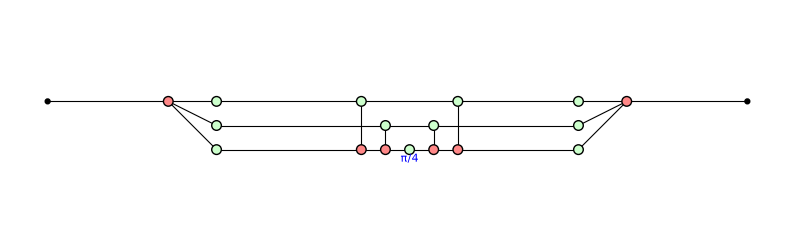

In [9]:
core = action.on_core()
print(sum(1 for v in core.composite.vertices() if core.composite.type(v) != VertexType.BOUNDARY), "spiders")
zx.draw_matplotlib(core.composite, figsize=(10, 3))

`reduce_gpf` with `gadgets=False` brings it to its normal form without combining the non-Clifford phases: the input on a green spider, which carries the logical bit, and the $T$ as a phase gadget, a red hub with a green leaf $\pi/4$. `phase_polynomial` adds the gadgets up as a polynomial in the bits they read: here one term, $\pi/4$ times the logical bit. A phase $\pi/4$ on the logical bit is $T$.

1 gadget(s); phase polynomial (units of pi): {'logical bit': '1/4'}


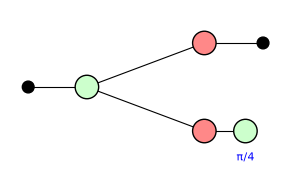

In [10]:
reduced = reduce_gpf(core.composite, gadgets=False)
poly, gadgets = phase_polynomial(reduced.graph)
(logical_bit,) = reduced.graph.neighbors(reduced.graph.inputs()[0])
print(len(gadgets), "gadget(s); phase polynomial (units of pi):",
      {' * '.join('logical bit' if v == ('z', logical_bit) else str(v) for v in m): str(c) for m, c in poly.items()})
zx.draw_matplotlib(reduced.to_graph(), figsize=(3.5, 2))

The tool names it as in Question 2: the reduced map depends on no measurement result, so there is one class of runs; its $2 \times 2$ matrix, scaled so that the first entry is 1, is $\mathrm{diag}(1, e^{i\pi/4})$, which is $T$. The check that the block keeps the code passes.

In [11]:
m = action.matrix(action.branches()[0].outcomes)
print("matrix:", np.round(m / m[0, 0], 3).tolist())
print("stays in the code:", action.stays_in_code())
print("verdict:", action.verdict())

matrix: [[(1+0j), 0j], [0j, (0.707+0.707j)]]
stays in the code: True
verdict: deterministic: every run implements T


## Step 6: the same answer without the normal form

The tool can also glue the block between the ideal encoders themselves (`via='encoder'`): the same equation, without splitting off $U_O$. It gives the same $T$; its composite is larger, since the $S$ is part of both encoders and stays in it, around the block. The test suite compares the two routes on random codes that are not CSS (`tests/test_iapnf.py`).

In [12]:
other = logical_action(p.block_graph(0, 2, classical=False), p.code_at(1), p.code_at(2), via='encoder')
print("through the ideal encoders:", other.verdict())
count = lambda g: sum(1 for v in g.vertices() if g.type(v) != VertexType.BOUNDARY)
print("composite spiders: through the normal forms", count(action.composite), "| through the ideal encoders", count(other.composite))

through the ideal encoders: deterministic: every run implements T
composite spiders: through the normal forms 17 | through the ideal encoders 25


## Summary

| step | what the tool does | here |
|---|---|---|
| 1 | read the code (`code_at`) | stabilizers $+IXX$, $+YXI$; $\bar X = X_1$, $\bar Z = Z_0Z_1Z_2$; not CSS |
| 2 | the Choi state's generators: $I \otimes g$, $X_i \otimes \bar X_i$, $Z_i \otimes \bar Z_i$ | 4 generators on 4 qubits |
| 3 | its reduced AP form (`reduced_ap_form`): $(B, b)$ and $A$, by Gaussian elimination | one row $\{\mathrm{in}_0, 0, 1, 2\}$; $A_{00} = 1$ |
| 4 | the IAPNF (`iap_normal_form`): $E = U_O \cdot C \cdot U_I$ | $U_I$ empty; $C$ the repetition code; $U_O = S$ on qubit 0 |
| 5 | the logical action through the normal forms: $U_O$ cancels around the diagonal block, the block is checked on $C$ | one gadget, $\pi/4$ on the logical bit: $T$ |
| 6 | the same through the ideal encoders | $T$ |